# 06 — From RUL predictions to maintenance decisions (FD001 and FD003)

A RUL prediction is only useful if it leads to a **decision**: should this engine go to maintenance now, or can it keep flying?

**Scenario:**
- Every engine is **checked every 20 cycles**.
- At each check, the LSTM predicts the RUL from the last 30 cycles.
- **AI rule:** send the engine to maintenance if `predicted RUL ≤ threshold`.

**Two kinds of mistakes:**
- **Missed failure** (dangerous): the engine is *not* sent, but its true RUL is **below 20**, so it fails before the next check.
- **Unnecessary removal** (costly): the engine is sent, but its true RUL was **20 or more**, so it would have safely reached the next check. The cycles of life that are thrown away are the **wasted life**.

We then:
1. evaluate a simple threshold rule;
2. add a **safety margin** based on the validation errors;
3. **sweep** the threshold and compare with a **fixed-interval** policy that uses no AI;
4. compare with the **course example's rule**.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Project root = parent of the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import FD001_SENSORS
from src.maintenance import build_checks, simulate_policy, summarize_outcomes
from src.metrics import rmse
from src.models import LSTMModel
from src.pipeline import prepare_subset
from src.training import predict, set_seed, train_model

FIG_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 0
RUL_CAP = 125
WINDOW_SIZE = 30
CHECK_INTERVAL = 20   # cycles between two checks
SUBSETS = ["FD001", "FD003"]

## 1. Train the LSTM

Same pipeline and settings as `05` (`prepare_subset`, all training windows, seed 0, early stopping with patience 10), so these are the same LSTMs we explained with SHAP. This takes about 2 minutes.

In [2]:
data = {}
models = {}

for subset in SUBSETS:
    data[subset] = prepare_subset(subset, window_size=WINDOW_SIZE, rul_cap=RUL_CAP, train_stride=1)
    d = data[subset]

    set_seed(SEED)
    model = LSTMModel(n_features=len(FD001_SENSORS))
    model, _ = train_model(model, d["X_train"], d["y_train"] / RUL_CAP, d["X_val"], d["y_val"] / RUL_CAP,
                           seed=SEED, verbose=False)
    models[subset] = model

    test_pred = predict(model, d["X_test"]) * RUL_CAP
    print(f"{subset}: LSTM test RMSE {rmse(d['y_test'], test_pred):.2f}")

FD001: LSTM test RMSE 15.14
FD003: LSTM test RMSE 16.26


## 2. The checks on the test engines

The C-MAPSS test engines stop at some point **before** failure, and we know their true RUL at every recorded cycle. We treat the **last recorded cycle as "today's check"**, and the earlier checks happened every 20 cycles before it (last − 20, last − 40, ...). At each check the LSTM only sees the cycles up to that check (`build_checks` in `src/maintenance.py`).

Then, engine by engine, we go through the checks in time order (`simulate_policy`):
- if the rule says **send**: the engine is removed. If its true RUL was **< 20** it is a *necessary removal*, otherwise an *unnecessary removal*. Its true RUL at that moment is the **wasted life**;
- if the rule says **keep** but the true RUL is **< 20**: **missed failure**;
- if nothing happens until the last check: the engine is **still in service** at the end of the data. We cannot know what happens after the last recorded cycle.

**Important limitation:** a missed failure is only possible for engines whose true RUL at "today's check" is below 20. Only **13 test engines per subset** are in that situation; most test engines are cut off far from failure. So the missed-failure counts below are small numbers (0 to 13), and one engine more or less matters.

In [3]:
checks = {}
X_checks = {}
predicted = {}

for subset in SUBSETS:
    X_checks[subset], checks[subset] = build_checks(
        data[subset]["test_part"], FD001_SENSORS, WINDOW_SIZE, CHECK_INTERVAL)
    # One LSTM prediction per check, in cycles
    predicted[subset] = predict(models[subset], X_checks[subset]) * RUL_CAP
    checks[subset]["predicted_rul"] = predicted[subset]

    at_risk = (data[subset]["y_test"] < CHECK_INTERVAL).sum()
    print(f"{subset}: {len(checks[subset])} checks on {checks[subset]['unit'].nunique()} engines | "
          f"engines that fail before the next check if not removed: {at_risk}")

checks["FD001"].head(8)

FD001: 604 checks on 100 engines | engines that fail before the next check if not removed: 13
FD003: 781 checks on 100 engines | engines that fail before the next check if not removed: 13


,unit,cycle,true_rul,predicted_rul
0,1,31,112,112.789513
1,2,29,118,124.117241
2,2,49,98,122.566910
3,3,26,169,95.869469
4,3,46,149,108.013931
5,3,66,129,122.735825
6,3,86,109,123.575569
7,3,106,89,105.878494


### Reference: the perfect policy

If we knew the true RUL, we would send an engine exactly when its true RUL is below 20. This gives **no missed failure** and the smallest possible waste: every removed engine still had 0–19 cycles left. It is the best any policy can do with checks every 20 cycles.

In [4]:
def evaluate(subset, send):
    """Simulate a decision (one True/False per check) and return the summary."""
    outcomes = simulate_policy(checks[subset], send, CHECK_INTERVAL)
    return summarize_outcomes(outcomes)


rows = []
for subset in SUBSETS:
    perfect_send = (checks[subset]["true_rul"] < CHECK_INTERVAL).values
    rows.append({"subset": subset, "policy": "Perfect (knows the true RUL)", **evaluate(subset, perfect_send)})
pd.DataFrame(rows).set_index(["subset", "policy"]).round(1)

,,missed failures,necessary removals,unnecessary removals,in service,avg wasted life,total wasted life
subset,policy,,,,,,
FD001,Perfect (knows the true RUL),0,13,0,87,11.8,153.0
FD003,Perfect (knows the true RUL),0,13,0,87,11.7,152.0


## 3. The simple AI rule: send if predicted RUL ≤ 20

The most natural rule: the next check is in 20 cycles, so send the engine if the model predicts fewer than 20 cycles left.

In [5]:
rows = []
for subset in SUBSETS:
    send = (checks[subset]["predicted_rul"] <= 20).values
    rows.append({"subset": subset, "policy": "AI: predicted RUL <= 20", **evaluate(subset, send)})
pd.DataFrame(rows).set_index(["subset", "policy"]).round(1)

,,missed failures,necessary removals,unnecessary removals,in service,avg wasted life,total wasted life
subset,policy,,,,,,
FD001,AI: predicted RUL <= 20,1,11,5,83,14.8,236.0
FD003,AI: predicted RUL <= 20,1,11,3,85,14.7,206.0


This rule trusts the prediction completely. But the LSTM has errors of ±15 cycles on average, so an engine with a true RUL of 10 can easily be predicted at 25 and kept in service. **A rule that is right on average is not safe**: we need a margin.

## 4. Safety margin from the validation errors

The dangerous error is **over-estimation** (predicted RUL > true RUL). We measure how large it gets on the **validation engines**, which the model did not train on. We do **not** use the test engines here, because they are what we evaluate on.

We only use validation windows with a true RUL below 125, i.e. outside the capped "healthy" plateau, since that is where maintenance decisions are made.

`error = predicted RUL − true RUL` (positive = too optimistic = dangerous)

**Rule with margin:** send if `predicted RUL − margin ≤ 20`, where the margin is a **percentile** of the validation error. For example, with the 90th percentile, the model over-estimates by more than the margin only in 10% of validation windows.

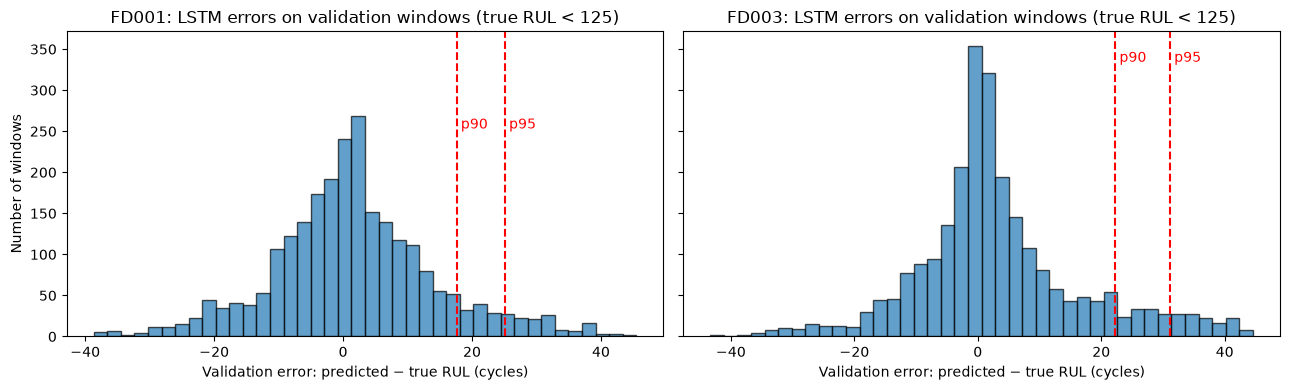

,p50 margin,p80 margin,p90 margin,p95 margin,p99 margin
FD001,1.0,10.3,17.600000,25.100000,36.5
FD003,1.2,11.2,22.299999,31.200001,40.5


In [6]:
margins = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, subset in zip(axes, SUBSETS):
    d = data[subset]
    val_pred = predict(models[subset], d["X_val"]) * RUL_CAP
    not_capped = d["y_val"] < RUL_CAP
    errors = val_pred[not_capped] - d["y_val"][not_capped]

    margins[subset] = {p: np.percentile(errors, p) for p in [50, 80, 90, 95, 99]}

    ax.hist(errors, bins=40, edgecolor="black", alpha=0.7)
    for p in [90, 95]:
        ax.axvline(margins[subset][p], color="red", linestyle="--")
        ax.text(margins[subset][p], ax.get_ylim()[1] * 0.9, f" p{p}", color="red")
    ax.set_xlabel("Validation error: predicted − true RUL (cycles)")
    ax.set_title(f"{subset}: LSTM errors on validation windows (true RUL < 125)")
axes[0].set_ylabel("Number of windows")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_validation_errors.png", dpi=150)
plt.show()

pd.DataFrame(margins).T.round(1).rename(columns=lambda p: f"p{p} margin")

In [7]:
rows = []
for subset in SUBSETS:
    for p, margin in margins[subset].items():
        send = (checks[subset]["predicted_rul"] - margin <= 20).values
        rows.append({"subset": subset, "margin": f"p{p} = {margin:.1f} cycles", **evaluate(subset, send)})

margin_table = pd.DataFrame(rows).set_index(["subset", "margin"]).round(1)
margin_table

missed failures  necessary removals  \
subset margin                                                   
FD001  p50 = 1.0 cycles                 1                  11   
       p80 = 10.3 cycles                0                   7   
       p90 = 17.6 cycles                0                   4   
       p95 = 25.1 cycles                0                   2   
       p99 = 36.5 cycles                0                   1   
FD003  p50 = 1.2 cycles                 1                  10   
       p80 = 11.2 cycles                0                   7   
       p90 = 22.3 cycles                0                   1   
       p95 = 31.2 cycles                0                   0   
       p99 = 40.5 cycles                0                   0   

                          unnecessary removals  in service  avg wasted life  \
subset margin                                                                 
FD001  p50 = 1.0 cycles                      5          83             14.8   
       p80 = 10.3 cycles                    19          74             24.1   
       p90 = 17.6 cycles                    23          73             28.7   
       p95 = 25.1 cycles                    30          68             35.4   
       p99 = 36.5 cycles                    34          65             44.4   
FD003  p50 = 1.2 cycles                      4          85             16.1   
       p80 = 11.2 cycles                    14          79             25.6   
       p90 = 22.3 cycles                    26          73             37.0   
       p95 = 31.2 cycles                    32          68             42.9   
       p99 = 40.5 cycles                    42          58             55.0   

                          total wasted life  
subset margin                                
FD001  p50 = 1.0 cycles               236.0  
       p80 = 10.3 cycles              627.0  
       p90 = 17.6 cycles              775.0  
       p95 = 25.1 cycles             1132.0  
       p99 = 36.5 cycles             1555.0  
FD003  p50 = 1.2 cycles               226.0  
       p80 = 11.2 cycles              537.0  
       p90 = 22.3 cycles             1000.0  
       p95 = 31.2 cycles             1374.0  
       p99 = 40.5 cycles             2312.0

**What the margin does:**
- **No margin or p50 (≈ 1 cycle):** 1 missed failure in each subset. This is the same as the simple rule.
- **p80 margin (≈ 10–11 cycles):** **0 missed failures** in both subsets. The price is more unnecessary removals (FD001: 5 → 19) and about 2.5× more total wasted life (236 → 627 cycles).
- **p90 / p95 / p99:** still 0 missed failures, but the waste keeps growing quickly (up to 1,555 cycles on FD001 and 2,312 on FD003 with p99).

With only 13 engines at risk per subset, "0 missed failures with p80" is weak evidence. For a safety-critical decision, a **p90 or p95 margin** is a more prudent choice: the extra waste is the cost of being protected against the model's larger over-estimates.

## 5. Sweep: missed failures vs wasted life

A margin is just a way to raise the threshold. So we now **sweep the threshold** from 0 to 125 cycles and plot, for each value, the number of missed failures against the **total wasted life** of the fleet. Each point is one policy; points closer to the bottom-left corner are better.

We use the **total** wasted life (sum over all removed engines) on the x-axis, because the average can be misleading: a policy that removes only one engine, a little early, has a small average waste but many missed failures.

**Fixed-interval policy (no AI):** send every engine to maintenance once its age reaches `A` cycles, whatever its condition. This is classic preventive maintenance. We sweep `A` from 20 to 360 cycles.

In [8]:
thresholds = np.arange(0, 126, 5)
ages = np.arange(20, 361, 20)

sweep_rows = []
for subset in SUBSETS:
    c = checks[subset]
    for threshold in thresholds:
        send = (c["predicted_rul"] <= threshold).values
        sweep_rows.append({"subset": subset, "policy": "AI threshold", "parameter": threshold, **evaluate(subset, send)})
    for age in ages:
        send = (c["cycle"] >= age).values
        sweep_rows.append({"subset": subset, "policy": "Fixed interval", "parameter": age, **evaluate(subset, send)})

sweep = pd.DataFrame(sweep_rows)

## 6. The course example's rule

The course example uses:

`send to maintenance if current_time > predicted_rul − delta`

where `current_time` is the age of the engine (cycles since it started) and `delta` is a safety parameter. We implement it **exactly as written** and sweep `delta`. In the course code the model target is the remaining life, so `predicted_rul` is the predicted remaining life, as in our models.

Rewriting it: `predicted_rul < current_time + delta`. So the **threshold is not fixed: it grows with the age** of the engine. Our rule compares the predicted RUL with a fixed number of cycles (the time to the next check).

In [9]:
deltas = np.arange(-300, 101, 20)

for subset in SUBSETS:
    c = checks[subset]
    for delta in deltas:
        send = (c["cycle"] > c["predicted_rul"] - delta).values
        sweep_rows.append({"subset": subset, "policy": "Course rule", "parameter": delta, **evaluate(subset, send)})

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(METRICS_DIR / "06_policy_sweep.csv", index=False)

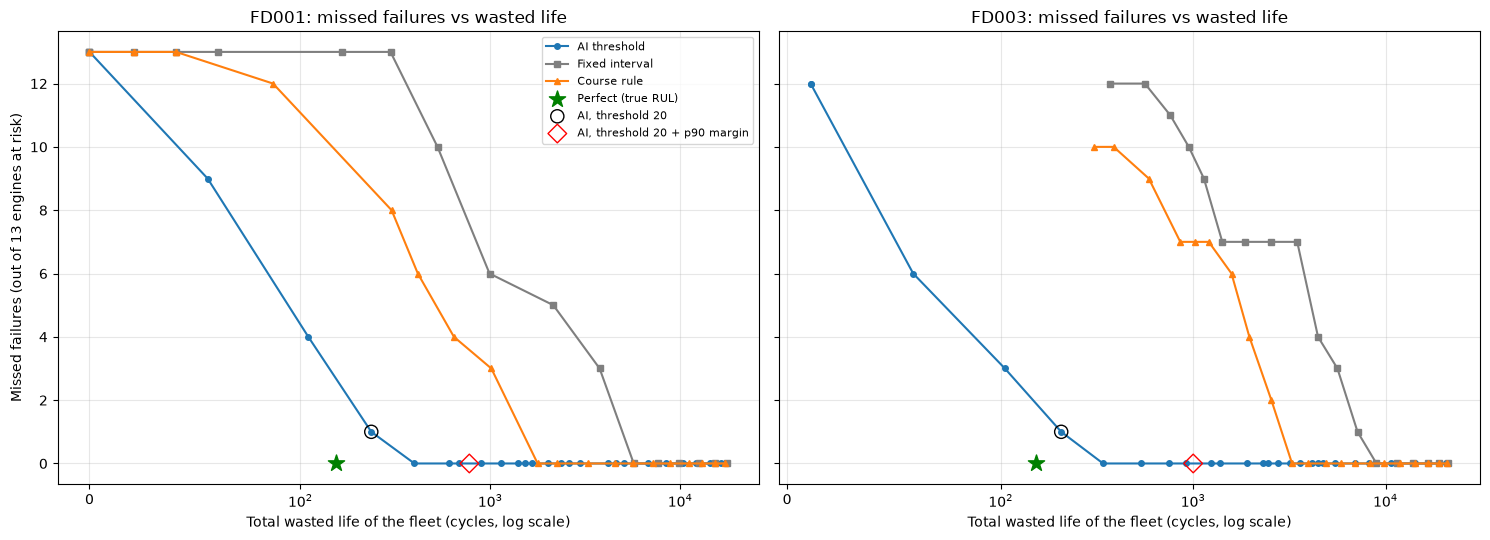

In [10]:
styles = {
    "AI threshold": dict(color="tab:blue", marker="o"),
    "Fixed interval": dict(color="tab:grey", marker="s"),
    "Course rule": dict(color="tab:orange", marker="^"),
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, subset in zip(axes, SUBSETS):
    for policy, style in styles.items():
        part = sweep[(sweep["subset"] == subset) & (sweep["policy"] == policy)]
        ax.plot(part["total wasted life"], part["missed failures"], label=policy, markersize=4, **style)

    # Perfect policy and two highlighted AI policies
    perfect = evaluate(subset, (checks[subset]["true_rul"] < CHECK_INTERVAL).values)
    ax.scatter(perfect["total wasted life"], perfect["missed failures"], s=150, marker="*",
               color="green", zorder=5, label="Perfect (true RUL)")
    naive = evaluate(subset, (checks[subset]["predicted_rul"] <= 20).values)
    ax.scatter(naive["total wasted life"], naive["missed failures"], s=90, facecolors="none",
               edgecolors="black", zorder=5, label="AI, threshold 20")
    p90 = margins[subset][90]
    with_margin = evaluate(subset, (checks[subset]["predicted_rul"] - p90 <= 20).values)
    ax.scatter(with_margin["total wasted life"], with_margin["missed failures"], s=90, marker="D",
               facecolors="none", edgecolors="red", zorder=5, label="AI, threshold 20 + p90 margin")

    ax.set_xscale("symlog", linthresh=100)
    ax.set_xlabel("Total wasted life of the fleet (cycles, log scale)")
    ax.set_title(f"{subset}: missed failures vs wasted life")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Missed failures (out of 13 engines at risk)")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_policy_tradeoff.png", dpi=150)
plt.show()

To compare the policies with one number, we look for each one at the **cheapest setting with zero missed failures** (smallest total wasted life among the settings that miss no failure).

In [11]:
safe = sweep[sweep["missed failures"] == 0]
best_safe = safe.loc[safe.groupby(["subset", "policy"])["total wasted life"].idxmin()]
best_safe = best_safe[["subset", "policy", "parameter", "necessary removals", "unnecessary removals",
                       "in service", "avg wasted life", "total wasted life"]]
best_safe.set_index(["subset", "policy"]).round(1)

parameter  necessary removals  unnecessary removals  \
subset policy                                                                
FD001  AI threshold           25                  12                    10   
       Course rule          -100                   4                    31   
       Fixed interval        120                   3                    60   
FD003  AI threshold           25                  10                     8   
       Course rule          -120                   4                    36   
       Fixed interval        120                   1                    64   

                       in service  avg wasted life  total wasted life  
subset policy                                                          
FD001  AI threshold            78             18.1              398.0  
       Course rule             65             50.7             1774.0  
       Fixed interval          37             90.3             5690.0  
FD003  AI threshold            82             18.9              340.0  
       Course rule             60             81.6             3266.0  
       Fixed interval          35            138.0             8968.0

## 7. Discussion

**1. With a safety margin, the LSTM rule misses no failure and wastes far less life than the alternatives.** Our recommended policy is "send if predicted RUL − p90 margin ≤ 20". The margin is chosen on the **validation** engines only, so the test result is a fair estimate:

| Total wasted life (0 missed failures) | AI rule + p90 margin | Course rule | Fixed interval |
|---|---|---|---|
| FD001 | **775** | 1,774 | 5,690 |
| FD003 | **1,000** | 3,266 | 8,968 |

For the course rule and the fixed interval we show their **best** setting with zero missed failures, chosen with hindsight on the test engines. This is optimistic for them, and the AI rule with a validation-based margin still wastes **2.3–3.3× less** life than the course rule and **7–9× less** than the fixed interval. To miss nothing, the fixed-interval policy has to remove *every* engine at age 120, including many that still had 100+ cycles left. The AI rule removes engines **based on their condition**, so it keeps healthy engines flying.

**2. A rule that is right on average is not safe.** The simple rule "send if predicted RUL ≤ 20" misses 1 failure in each subset, because the LSTM sometimes over-estimates the RUL. The validation margin fixes this, at the cost of more early removals (FD001: 5 → 23 unnecessary removals with p90).

*For comparison only:* with hindsight on the test engines, the cheapest AI threshold with zero missed failures is 25 cycles (398 and 340 wasted cycles). We cannot use it in practice, because it was chosen by looking at the test results. The gap between 775 and 398 is the **price of not knowing the test data in advance**.

**3. The course rule.** In the course code the model target is the remaining life, so `predicted_rul` is the predicted remaining life, and our literal implementation follows the course. **Read literally, the course rule compares engine age with remaining life; if `predicted_rul` is read as predicted failure time, it becomes equivalent to our threshold rule.**

Rewriting the literal rule as `predicted_rul < current_time + delta` shows that its threshold **grows with the age** of the engine. With the best safe value (delta ≈ −100), a young engine (age < 100) is never sent, whatever its prediction, and an old engine is sent even when the model predicts plenty of life. So it behaves partly like the fixed-interval policy, which is why its curve lies **between** the AI rule and the fixed interval.

Our rule compares the prediction with the **time to the next check** (20 cycles). That is the quantity the decision depends on: will the engine survive until we look at it again?

**Limitations.**
- Only 13 test engines per subset can fail before the next check; the others are cut off far from failure ("in service" at the end of the data). The missed-failure counts are therefore small and noisy.
- We count missed failures and wasted cycles separately. A real airline would put a **cost** on each (an in-flight shutdown costs far more than a few cycles of life) and choose the threshold that minimizes the total cost.
- One trained LSTM (seed 0) per subset; another seed would change the counts slightly.